# Intervalos de predicción por *conformal* (exploratorio)
### AVM · Distrito Centro (Rosario)

**Análisis complementario exploratorio** (§4.9.2) sobre el **modelo final** de PI1 (notebook 04, vía `modelo_final.py`).
Se calibra el cuantil conforme con los residuos OOF (escala log).

> Los mismos residuos OOF se usan para calibrar y evaluar: **no es una validación independiente** de la cobertura.


In [1]:
from pathlib import Path
import sys, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
ROOT=Path.cwd()
while not (ROOT/"data"/"processed").exists() and ROOT!=ROOT.parent: ROOT=ROOT.parent
sys.path.insert(0, str(ROOT/"scripts"/"modeling")); import modelo_final as mf   # modelo final de PI1 (notebook 04)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.dpi":120})
TAB=ROOT/"reports"/"tables"/"modelado"; FIG=ROOT/"reports"/"figures"/"resultados"
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
df=mf.cargar_matriz(ROOT); yv=pd.to_numeric(df["eda_precio_usd"],errors="coerce").values.astype(float)
ytil=mf.target_log(df); groups=df["building_cluster_id"].values; cols=mf.columnas_S4(df); X=df[cols]


## 1. Modelo final OOF y cuantil conforme (90 %)


In [2]:
oof=np.full(len(yv),np.nan)
for tr,va in GroupKFold(5).split(X,ytil,groups):
    oof[va]=mf.construir_modelo_final(cols,df).fit(X.iloc[tr],ytil[tr]).predict(X.iloc[va])
alpha=0.10; res=np.abs(ytil-oof); n=len(res); k=int(np.ceil((n+1)*(1-alpha))); q=np.sort(res)[min(k,n)-1]
lo=np.expm1(oof-q); hi=np.expm1(oof+q); dentro=(yv>=lo)&(yv<=hi); cob=dentro.mean()*100; amp=np.median((hi-lo)/np.expm1(oof))*100
print(f"[modelo final] R2 OOF={r2_score(ytil,oof):.3f} | q(log)={q:.3f} | cobertura={cob:.1f}% | ancho mediano ±{amp/2:.0f}%")
print("NOTA: mismos OOF para calibrar y evaluar -> NO es validación independiente.")


[modelo final] R2 OOF=0.902 | q(log)=0.338 | cobertura=90.0% | ancho mediano ±34%
NOTA: mismos OOF para calibrar y evaluar -> NO es validación independiente.


## 2. Cobertura y amplitud por segmento


,segmento,n,cobertura_%,ancho_rel_%
0,GLOBAL,4765,90.0,69
1,< 80k,1723,90.2,69
2,80–120k,751,92.3,69
3,120–180k,917,89.6,69
4,180–300k,905,90.1,69
5,> 300k,469,86.4,69


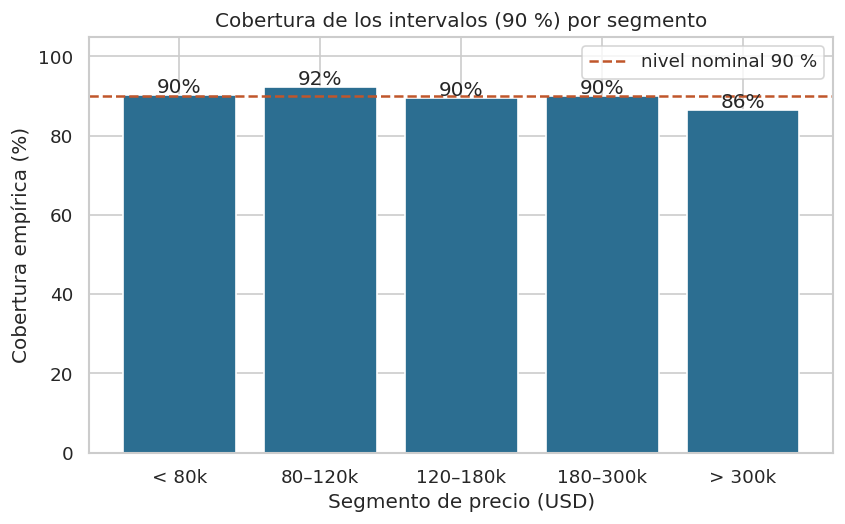

In [3]:
seg=pd.cut(yv,[0,80000,120000,180000,300000,np.inf],labels=["< 80k","80–120k","120–180k","180–300k","> 300k"])
rows=[{"segmento":"GLOBAL","n":len(yv),"cobertura_%":round(cob,1),"ancho_rel_%":round(amp)}]
for s in seg.categories:
    m=seg==s; rows.append({"segmento":s,"n":int(m.sum()),"cobertura_%":round(dentro[m].mean()*100,1),"ancho_rel_%":round(np.median((hi[m]-lo[m])/np.expm1(oof[m]))*100)})
cov=pd.DataFrame(rows); cov.to_csv(TAB/"conformal_cobertura.csv",index=False); display(cov)
fig,ax=plt.subplots(figsize=(8,4.5)); sub=cov[cov.segmento!="GLOBAL"]
ax.bar(sub["segmento"],sub["cobertura_%"],color="#2c6e91"); ax.axhline(90,color="#c0562b",ls="--",label="nivel nominal 90 %")
for i,v in enumerate(sub["cobertura_%"]): ax.text(i,v+0.6,f"{v:.0f}%",ha="center")
ax.set(ylim=(0,105),ylabel="Cobertura empírica (%)",xlabel="Segmento de precio (USD)",title="Cobertura de los intervalos (90 %) por segmento"); ax.legend()
fig.savefig(FIG/"r7_intervalos.png",bbox_inches="tight"); plt.show()
